# Sequential multiparity readout and central-boson AGP

This follows agp_measurement.py, using one preparation and evolution to read
M1 first and then each storage. Every mode keeps its own pair of readout lanes
in the raw JOB HDF5. There are no inverse swaps between readouts.

Run the acquisition cells you need. The configuration versions and measurement
defaults below come from the reference notebook; the experiment folder is new.
The sequential Experiment analyzes into self.data before normal JOB saving.
Sequential AGP classes read those JOBs directly and save the assembled layers.

In [29]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from experiments import CharacterizationRunner, MultimodeStation
from experiments.qsim.agp_sequential import CentralBosonAGPSequentialDisorderScan
from experiments.qsim.fock_population_sequential import (
    FockPopulationSequentialReadoutExperiment,
)
from experiments.qsim.multiparity_confusion_matrix_sequential import (
    MultiParityConfusionMatrixSequentialExperiment,
)
from experiments.qsim.notebook_helpers.defaults import (
    ACTIVE_RESET_DEFAULTS,
    FLOQUET_DEFAULTS,
)
from job_server import JobClient
from slab import AttrDict
from theory.qsim.central_boson import fixed_n_hamiltonian

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Station and worker

Constructing the runners does not submit measurements. Before acquisition, use
the usual queue check and daily readout baseline for the selected config.

In [30]:
user = "jonginn"
config_dict = {'hardware_config': 'CFG-HW-20261113-00031',
 'multiphoton_config': 'CFG-MP-20260121-00001',
 'man1_storage_swap': 'CFG-M1-20261113-00018',
 'floquet_storage_swap': 'CFG-FL-20261111-00111'}

client = JobClient()
health = client.health_check()
print(f"Server status: {health['status']}")
client.print_queue()

station = MultimodeStation(
    user=user,
    experiment_name="261105AGPSequential",
    project="AGP",
    log_measurements=True,
    hardware_config=config_dict["hardware_config"],
    multiphoton_config=config_dict["multiphoton_config"],
    storage_man_file=config_dict["man1_storage_swap"],
    floquet_file=config_dict["floquet_storage_swap"],
)

Server status: healthy

=== Job Queue ===

Running: JOB-20261113-00467
  User: jonginn
  Experiment: FockPopulationExperiment
  Started: 2026-11-13T14:50:30.161384

Pending: 0 jobs

[STATION] Using hardware_config version: CFG-HW-20261113-00031
[STATION] Using multiphoton_config version: CFG-MP-20260121-00001
[STATION] Using man1_storage_swap version: CFG-M1-20261113-00018
[STATION] Using floquet_storage_swap version: CFG-FL-20261111-00111
[STATION] Lab-notebook vault: G:\Shared drives\SLab\Multimode
Data, plots, logs will be stored in: C:\experiments\261105AGPSequential
Hardware configs will be read from C:\python\multimode_expts\configs\versions\hardware_config\CFG-HW-20261113-00031.yml
dict_keys(['Pyro.NameServer', 'Qick101'])
QICK running on ZCU216, software version 0.2.291

Firmware configuration (built Tue Oct 15 12:06:51 2024):

	Global clocks (MHz): tProcessor 430.080, RF reference 245.760

	7 signal generator channels:
	0:	axis_signal_gen_v6 - envelope memory 32768 samples (5.

In [34]:
STORAGE_MODES = [1]
RO_STORS = [0, *STORAGE_MODES]
common_defaults = AttrDict(dict(
    expts=1, reps=1, rounds=1, qubits=[0], f0g1_cavity=1,
    normalize=False, active_reset=True, man_reset=True,
    storage_reset=STORAGE_MODES, pre_relax_delay=100, relax_delay=200,
    postpulse=True, init_fock=False, init_stor=0, ro_stor=0,
    readout="multiparity", parity_fast=False,
    cond_sec_phase=-90, phase_second_pulse=180,
    swap_stors=STORAGE_MODES, update_phases=True,
    detunings= [0]#[0.0, 0.0, 0.0, 0.0],
))
common_defaults.update(ACTIVE_RESET_DEFAULTS)
common_defaults.update(FLOQUET_DEFAULTS)

population_defaults = AttrDict(dict(
    common_defaults, prepulse=False, occupations=[3,0],#[3, 0, 0, 0, 0],
    ro_stors=RO_STORS, floquet_cycles=[0], swept_params=["floquet_cycle"],
    multiparity_confusion_matrix=None, multiparity_confusion_matrices=None,
))
calibration_defaults = AttrDict(dict(
    population_defaults, background_occupations=[0,0]#[0, 0, 0, 0, 0],
))

In [35]:
confusion_matrix_runner = CharacterizationRunner(
    station=station,
    ExptClass=MultiParityConfusionMatrixSequentialExperiment,
    default_expt_cfg=calibration_defaults,
    job_client=client,
    use_queue=True,
    show=False,
)

population_runner = CharacterizationRunner(
    station=station,
    ExptClass=FockPopulationSequentialReadoutExperiment,
    default_expt_cfg=population_defaults,
    job_client=client,
    use_queue=True,
    show=False,
)

## 2. Calibrate every readout step

One JOB sweeps four target preparations per readout step, using the full
readout order. With five measured modes this gives 20 settings. Other modes
use the specified background occupations. The tensor axes are
(prepared number, measured label, readout step), with shape (4, 4, 5).

Pass the calibration HDF5 filename as multiparity_confusion_matrices. The legacy
single-mode calibration is kept separate and is not broadcast to all steps.

In [36]:
calibration_expt = confusion_matrix_runner.execute(
    reps=6000, postprocess=False,
    go_kwargs=dict(analyze=True, save=True),
)
print(calibration_expt.fname)

Job submitted: JOB-20261113-00473 (queue position: 1)

[0.0s] Job JOB-20261113-00473: pending

[26.1s] Job JOB-20261113-00473: running
[WORKER] Loading MultiParityConfusionMatrixSequentialExperiment from experiments.qsim.multiparity_confusion_matrix_sequential
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261113-00473_MultiParityConfusionMatrixSequentialExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.4mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
 88%|█████████████████▌  | 7/8 [00:18<00:02,  2.69s/it]
[54.2s] Job JOB-20261113-00473: completed
100%|████████████████████| 8/8 [00:21<00:00,  2.69s/it]
Saving C:\experiments\261105AGPSequential\data\JOB-20261113-00473_MultiParityConfusionMatrixSequentialExperiment.h5
[WORKER] Saving expt object to: C:\experiments\261105AGPSequential\expt_objs\JOB-20261113-00473_expt.pkl

Job completed! Data: C:\experiments\261105AGPSequential\data\JOB-20261113-00473_Mult

(<Figure size 800x400 with 4 Axes>,
 array([[<Axes: title={'center': 'M1, step 0'}, xlabel='Measured label', ylabel='Prepared number'>,
         <Axes: title={'center': 'S1, step 1'}, xlabel='Measured label', ylabel='Prepared number'>]],
       dtype=object))

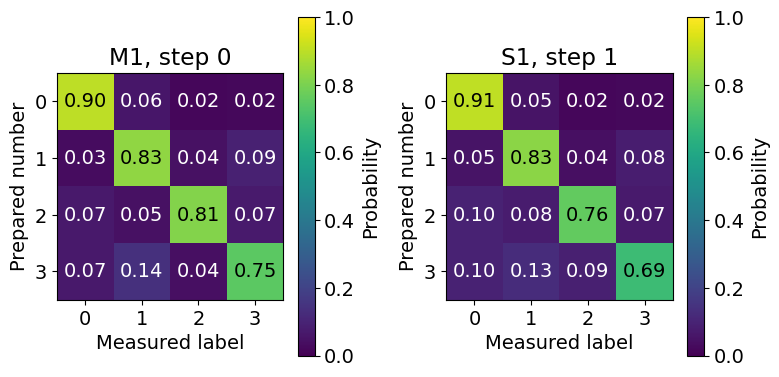

In [37]:
calibration_expt.display()

In [38]:
CONFUSION_MATRIX_FNAME = str(calibration_expt.fname)
# To reuse a saved calibration, replace the assignment above with its full HDF5 filename.

## 3. Optional population walk: all final modes in one JOB

Each cycle point and repetition still uses a fresh preparation. Within a shot,
all final populations are read in RO_STORS order. For total photon number 3,
number modulo four agrees with photon number.

In [39]:
swap_stors = list(STORAGE_MODES)
meas_stors = list(RO_STORS)
occupations = [3, 0]#[3, 0, 0, 0, 0]
detunings = [0]#[0.0, 0.0, 0.0, 0.0]  # MHz
floquet_cycles = list(range(0, 2, 2))

In [40]:
walk_expt = population_runner.execute(
    reps=1000,
    occupations=occupations,
    swap_stors=swap_stors,
    storage_reset=swap_stors,
    ro_stors=meas_stors,
    detunings=detunings,
    floquet_cycles=floquet_cycles,
    multiparity_confusion_matrices=CONFUSION_MATRIX_FNAME,
    postprocess=False, show=False, log=True,
    go_kwargs=dict(analyze=True, save=True),
)
print(walk_expt.fname)

Job submitted: JOB-20261113-00479 (queue position: 1)

[0.0s] Job JOB-20261113-00479: pending

[78.3s] Job JOB-20261113-00479: running
[WORKER] Loading FockPopulationSequentialReadoutExperiment from experiments.qsim.fock_population_sequential
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261113-00479_FockPopulationSequentialReadoutExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.4mA according to hardware_cfg yaml...

[86.3s] Job JOB-20261113-00479: completed
[WORKER] Done setting coupler current
100%|████████████████████| 1/1 [00:00<00:00,  1.58it/s]
Saving C:\experiments\261105AGPSequential\data\JOB-20261113-00479_FockPopulationSequentialReadoutExperiment.h5
[WORKER] Saving expt object to: C:\experiments\261105AGPSequential\expt_objs\JOB-20261113-00479_expt.pkl

Job completed! Data: C:\experiments\261105AGPSequential\data\JOB-20261113-00479_FockPopulationSequentialReadoutExperiment.h5
[log_measurement] Appended JOB-20261113-00

In [43]:
walk_expt.data['n_mean_corrected']

array([[2.96447561, 0.34894034]])

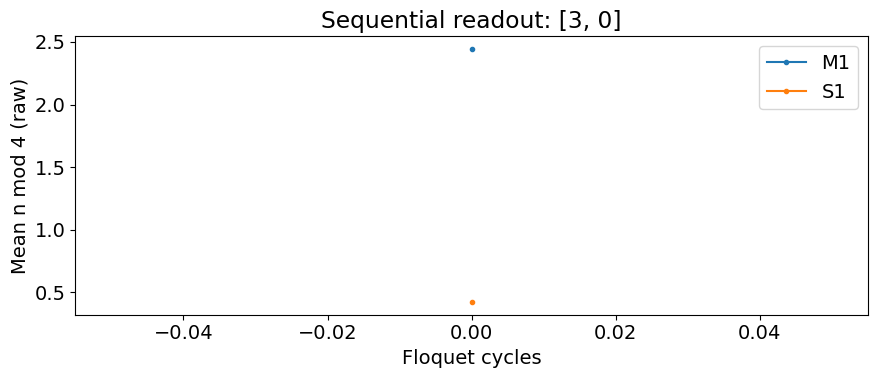

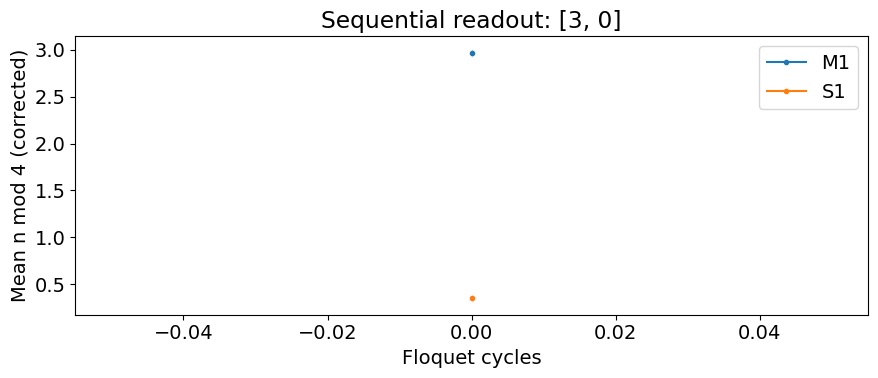

In [41]:
walk_expt.display(raw=True)
walk_expt.display()
plt.show()

In [16]:
KERR_KHZ = -30.0  # Same signed physical Kerr convention as agp_measurement.py.

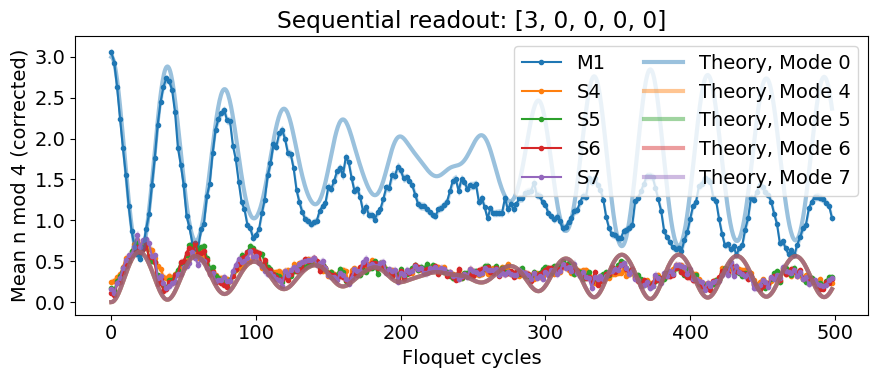

In [17]:
settings = walk_expt.cfg.expt
timing = walk_expt.recorded_derived_params()
storages = list(settings.swap_stors)
couplings_mhz = np.array([timing["couplings_MHz"][storage - 1] for storage in storages])
if settings.get("zero_floquet_gain", False):
    couplings_mhz[:] = 0.
detunings_mhz = settings.get("detunings")
if detunings_mhz is None or detunings_mhz is False or len(detunings_mhz) == 0:
    detunings_mhz = [0.] * len(storages)
model = fixed_n_hamiltonian(
    photon_number=sum(settings.occupations), mode_count=1 + len(storages),
    detunings=detunings_mhz, couplings_MHz=couplings_mhz,
    physical_kerr_MHz=KERR_KHZ / 1000,
)
cycles = np.asarray(walk_expt.data["xpts"], dtype=float)
theory_cycles = np.linspace(cycles.min(), cycles.max(), max(1000, len(cycles)))
time_us = theory_cycles * timing["floquet_cycle_us"]
initial_index = model.fock_index[tuple(settings.occupations)]
eigenstate_amplitudes = model.states[initial_index, :].conj()
phases = np.exp(-2j * np.pi * model.energies_MHz[:, None] * time_us[None, :])
state = model.states @ (eigenstate_amplitudes[:, None] * phases)
probability = np.abs(state) ** 2
theory_populations = probability.T @ np.asarray(model.fock_basis)
walk_fig, walk_axis = walk_expt.display()
for step, mode in enumerate(walk_expt.data["ro_stors"]):
    mode_index = [0, *storages].index(mode)
    color = walk_axis.lines[step].get_color()
    walk_axis.plot(theory_cycles, theory_populations[:, mode_index],
                   color=color, alpha=.45, linewidth=3, label=f"Theory, Mode {mode}")
walk_axis.legend(ncol=2)
walk_fig.tight_layout()
plt.show()

## 4. AGP measurements and assembled layers

from_pattern() plans the initial states and normalizes the disorder pattern.
acquire() measures the union of required initial states once per W.
Every JOB reads RO_STORS, and all directions share those original JOBs.
With N=3 and directions [0, 4, 5, 6, 7], this is 35 JOBs per W.
Each completed W saves all directions together before continuing.

Choose a fresh SCAN_NAME before a new run. Named assembled files are never
overwritten. One W manifest references its unique population JOBs.

In [20]:
TOTAL_PHOTONS = 3
AGP_DIRECTIONS = [0, 4, 5, 6, 7]  # 0: M1 Kerr; storage numbers: 4, 5, 6, 7.
DISORDER_RMS_KHZ = [0, 11, 18, 25]
AGP_REPS = 500
AGP_CYCLES = list(range(0, 800, 4))
AGP_BATCH_SIZE = 1
AGP_MU_KHZ = 10  # Cutoff in kHz; None uses the existing AGP default axis.
SCAN_NAME = "20261112_sequential_n3_pilot"  # Edit for each new measurement run.

DISORDER_PATTERN = np.array([-0.70675335, 0.19463085, -1.03457499, 1.54669749])
DISORDER_PATTERN -= np.mean(DISORDER_PATTERN)

In [21]:
scan = CentralBosonAGPSequentialDisorderScan.from_pattern(
    DISORDER_RMS_KHZ, DISORDER_PATTERN,
    photon_sector_number=TOTAL_PHOTONS,
    direction=AGP_DIRECTIONS,
    ro_stors=RO_STORS,
    swap_stors=STORAGE_MODES,
    cycles=AGP_CYCLES,
    calibration=CONFUSION_MATRIX_FNAME,
    notes="Central-boson correlations, sequential readout",
)
manifest_path = scan.acquire(
    population_runner, name=SCAN_NAME,
    analyze_kwargs=dict(mu=AGP_MU_KHZ),
    batch_size=AGP_BATCH_SIZE, reps=AGP_REPS,
    storage_reset=STORAGE_MODES, postprocess=False, show=False, log=True,
    go_kwargs=dict(analyze=True, save=True),
)
print(manifest_path)

batch 1: 1 jobs
Job submitted: JOB-20261112-00169 (queue position: 1)
[WORKER] Loading FockPopulationSequentialReadoutExperiment from experiments.qsim.fock_population_sequential
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261112-00169_FockPopulationSequentialReadoutExperiment.h5
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
100%|█| 200/200 [02:03<00:00,  
Saving C:\experiments\261105AGPSequential\data\JOB-20261112-00169_FockPopulationSequentialReadoutExperiment.h5
[WORKER] Saving expt object to: C:\experiments\261105AGPSequential\expt_objs\JOB-20261112-00169_expt.pkl
[log_measurement] Appended JOB-20261112-00169 to G:\Shared drives\SLab\Multimode\Lab\jonginn\AGP\2026\11\2026-11-12.md
batch 2: 1 jobs
Job submitted: JOB-20261112-00170 (queue position: 1)
[WORKER] Loading FockPopulationSequentialReadoutExperiment from experiments.qsim.fock_population_sequential
[W

RuntimeError: Job JOB-20261112-00171 failed: Job cancelled by user (Ctrl+C)

In [ ]:
scan.display()
scan.display_traces()
plt.show()

## 5. Optional reload for analysis

Raw shots remain in the sequential JOB files. from_manifest restores the
assembled layers and their inputs for reanalysis without saving another copy.

In [ ]:
reloaded_scan = CentralBosonAGPSequentialDisorderScan.from_manifest(manifest_path)
reloaded_scan.analyze(mu=AGP_MU_KHZ)
reloaded_scan.display()
plt.show()

## Module gaps

No notebook-local helpers are needed. Calibration and shared acquisition across
directions live in the Experiment classes.